# DemandPulse
## Large-Scale Retail Demand Forecasting and Inventory Intelligence

**Notebook:** `01_demandpulse_data_and_forecasting.ipynb`

This notebook implements a production-oriented forecasting workflow over the Hugging Face dataset **`Dingdong-Inc/FreshRetailNet-50K`**. It is intentionally structured as a professional data-science artifact rather than a beginner tutorial.

Core principles:

- remote streaming access; no manual dataset download
- deterministic sampling of complete `(store_id, product_id)` series
- explicit schema and data-quality checks
- temporal validation only
- strict target-leakage controls
- fixed-origin multi-day backtesting
- mandatory naive baselines before machine learning
- one global LightGBM model across many series
- separate production-like and oracle-weather experiments
- untouched official `eval` holdout until final evaluation
- reproducible artifacts, diagnostics, and failure analysis

> Dataset reference: https://huggingface.co/datasets/Dingdong-Inc/FreshRetailNet-50K

In [1]:
# %pip install -q "datasets>=3.0" "pandas>=2.0" "numpy>=1.24" "pyarrow>=14" "matplotlib>=3.7" "scikit-learn>=1.3" "lightgbm>=4.0" "tqdm>=4.66"

## 1. Environment and reproducibility

The environment cell records core package versions and fixes random seeds. The notebook does not globally suppress warnings; warnings should remain visible unless a specific warning is understood and locally handled.

In [2]:
import hashlib
import random
import sys
from pathlib import Path

import datasets
from datasets import load_dataset
from IPython.display import Markdown, display
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tqdm.auto import tqdm

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

print(f"Python      : {sys.version.split()[0]}")
print(f"datasets    : {datasets.__version__}")
print(f"pandas      : {pd.__version__}")
print(f"numpy       : {np.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"lightgbm    : {lgb.__version__}")

D:\DemandPulse\DemandPulse\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python      : 3.10.11
datasets    : 5.0.1
pandas      : 2.3.3
numpy       : 2.2.6
scikit-learn: 1.7.2
lightgbm    : 4.7.0


## 2. Configuration

`SERIES_SAMPLE_PERCENT` selects **entire store-product time series**, not the first fraction of rows. Set it to `100` for full-data experiments. The deterministic SHA-256 rule is shared by `train` and `eval`, so entity selection is reproducible and independent of source row ordering.

In [3]:
DATASET_ID = "Dingdong-Inc/FreshRetailNet-50K"
RANDOM_STATE = 42
SERIES_SAMPLE_PERCENT = 30
FORECAST_HORIZON = 7
N_BACKTEST_FOLDS = 3

# Operational settings. These do not change the scientific definition of the experiment.
STREAM_BATCH_SIZE = 50_000
EARLY_STOP_DAYS = 7
EARLY_STOPPING_ROUNDS = 100

assert 0 < SERIES_SAMPLE_PERCENT <= 100, "SERIES_SAMPLE_PERCENT must be in (0, 100]."
assert FORECAST_HORIZON >= 1, "FORECAST_HORIZON must be >= 1."
assert N_BACKTEST_FOLDS >= 1, "N_BACKTEST_FOLDS must be >= 1."

REPORTS_DIR = Path("reports")
FIGURES_DIR = REPORTS_DIR / "figures"
TABLES_DIR = REPORTS_DIR / "tables"
MODELS_DIR = Path("models")
for directory in (REPORTS_DIR, FIGURES_DIR, TABLES_DIR, MODELS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print(f"Dataset: {DATASET_ID}")
print(f"Series sample: {SERIES_SAMPLE_PERCENT}%")
print(f"Forecast horizon: {FORECAST_HORIZON} days")
print(f"Backtest folds: {N_BACKTEST_FOLDS}")

Dataset: Dingdong-Inc/FreshRetailNet-50K
Series sample: 30%
Forecast horizon: 7 days
Backtest folds: 3


## 3. Remote streaming access and schema validation

Hugging Face streaming returns an `IterableDataset`. It should be iterated progressively; it is not a normal random-access pandas DataFrame.

The dataset card currently documents 19 fields, 4.5M rows in `train`, and 350K rows in `eval`. We still validate the returned schema at runtime rather than trusting documentation blindly.

In [4]:
REQUIRED_COLUMNS = [
    "city_id",
    "store_id",
    "management_group_id",
    "first_category_id",
    "second_category_id",
    "third_category_id",
    "product_id",
    "dt",
    "sale_amount",
    "hours_sale",
    "stock_hour6_22_cnt",
    "hours_stock_status",
    "discount",
    "holiday_flag",
    "activity_flag",
    "precpt",
    "avg_temperature",
    "avg_humidity",
    "avg_wind_level",
]

SERIES_KEYS = ["store_id", "product_id"]
ROW_KEY = ["store_id", "product_id", "dt"]
ID_COLUMNS = [
    "city_id",
    "store_id",
    "management_group_id",
    "first_category_id",
    "second_category_id",
    "third_category_id",
    "product_id",
]
WEATHER_COLUMNS = ["precpt", "avg_temperature", "avg_humidity", "avg_wind_level"]
SAME_DAY_LEAKAGE_COLUMNS = ["hours_sale", "hours_stock_status", "stock_hour6_22_cnt"]

train_stream = load_dataset(DATASET_ID, split="train", streaming=True)
eval_stream = load_dataset(DATASET_ID, split="eval", streaming=True)


def validate_stream_schema(stream, split_name):
    if getattr(stream, "features", None) is not None:
        returned_columns = list(stream.features.keys())
        schema_types = {name: str(dtype) for name, dtype in stream.features.items()}
    else:
        first = next(iter(stream))
        returned_columns = list(first.keys())
        schema_types = {name: type(value).__name__ for name, value in first.items()}

    missing = sorted(set(REQUIRED_COLUMNS) - set(returned_columns))
    assert not missing, (
        f"{split_name} is missing required columns: {missing}. "
        f"Returned columns: {returned_columns}"
    )
    return returned_columns, schema_types


train_columns, train_schema_types = validate_stream_schema(train_stream, "train")
eval_columns, eval_schema_types = validate_stream_schema(eval_stream, "eval")

assert set(train_columns) == set(eval_columns), (
    "Train/eval schemas differ. "
    f"Only in train: {sorted(set(train_columns) - set(eval_columns))}; "
    f"only in eval: {sorted(set(eval_columns) - set(train_columns))}."
)

schema_table = pd.DataFrame({
    "column": REQUIRED_COLUMNS,
    "train_type": [train_schema_types[c] for c in REQUIRED_COLUMNS],
    "eval_type": [eval_schema_types[c] for c in REQUIRED_COLUMNS],
})
display(schema_table)

,column,train_type,eval_type
0,city_id,Value('int64'),Value('int64')
1,store_id,Value('int64'),Value('int64')
2,management_group_id,Value('int64'),Value('int64')
3,first_category_id,Value('int64'),Value('int64')
4,second_category_id,Value('int64'),Value('int64')
5,third_category_id,Value('int64'),Value('int64')
6,product_id,Value('int64'),Value('int64')
7,dt,Value('string'),Value('string')
8,sale_amount,Value('float64'),Value('float64')
9,hours_sale,List(Value('float64')),List(Value('float64'))


### Streaming inspection before materialization

The preview shows five examples as dictionaries of keys, Python value types, and representative values. Sequence-valued fields are truncated in the display only.

In [5]:
def representative_value(value, max_items=4):
    if isinstance(value, (list, tuple)):
        head = value[:max_items]
        return f"{head} ... (len={len(value)})"
    return value


examples = list(train_stream.take(5))
inspection_rows = []
for i, example in enumerate(examples, start=1):
    inspection_rows.append({
        "example": i,
        "keys": list(example.keys()),
        "python_types": {k: type(v).__name__ for k, v in example.items()},
        "representative_values": {k: representative_value(v) for k, v in example.items()},
    })

display(pd.DataFrame(inspection_rows))
print(type(train_stream))
print("Streaming datasets are iterable and should not be treated as random-access pandas tables.")

,example,keys,python_types,representative_values
0,1,"[city_id, store_id, management_group_id, first...","{'city_id': 'int', 'store_id': 'int', 'managem...","{'city_id': 0, 'store_id': 0, 'management_grou..."
1,2,"[city_id, store_id, management_group_id, first...","{'city_id': 'int', 'store_id': 'int', 'managem...","{'city_id': 0, 'store_id': 0, 'management_grou..."
2,3,"[city_id, store_id, management_group_id, first...","{'city_id': 'int', 'store_id': 'int', 'managem...","{'city_id': 0, 'store_id': 0, 'management_grou..."
3,4,"[city_id, store_id, management_group_id, first...","{'city_id': 'int', 'store_id': 'int', 'managem...","{'city_id': 0, 'store_id': 0, 'management_grou..."
4,5,"[city_id, store_id, management_group_id, first...","{'city_id': 'int', 'store_id': 'int', 'managem...","{'city_id': 0, 'store_id': 0, 'management_grou..."


<class 'datasets.iterable_dataset.IterableDataset'>
Streaming datasets are iterable and should not be treated as random-access pandas tables.


## 4. Deterministic series sampling and safe materialization

The two hourly sequence columns, `hours_sale` and `hours_stock_status`, are verified in the remote schema but intentionally **not retained in the analytical pandas DataFrames**. They are same-day leakage fields and are relatively expensive nested objects. Their missingness is still counted while streaming.

`stock_hour6_22_cnt` is retained because it is required for stockout analysis and for constructing **historical** lagged stockout features.

In [6]:
MATERIALIZED_COLUMNS = [
    c for c in REQUIRED_COLUMNS if c not in {"hours_sale", "hours_stock_status"}
]


def series_selected(store_id, product_id, percent, cache):
    """Stable series-level selection with 0.01 percentage-point resolution."""
    if percent >= 100:
        return True
    cache_key = (store_id, product_id)
    if cache_key not in cache:
        token = f"{store_id}-{product_id}".encode("utf-8")
        digest = hashlib.sha256(token).digest()
        bucket = int.from_bytes(digest[:8], byteorder="big", signed=False) % 10_000
        cache[cache_key] = bucket < int(round(percent * 100))
    return cache[cache_key]


def materialize_stream(stream, split_name, sample_percent, batch_size=50_000):
    """
    Materialize a deterministic subset of complete store-product series.
    """
    import time
    if not hasattr(stream, "batch"):
        raise RuntimeError(
            "This notebook expects a recent Hugging Face datasets version with IterableDataset.batch(). "
            "Re-run the install cell and restart the kernel if necessary."
        )

    frames = []
    selection_cache = {}
    selected_missing_counts = {c: 0 for c in REQUIRED_COLUMNS}
    rows_processed = 0
    rows_selected = 0

    max_retries = 5
    for attempt in range(max_retries):
        try:
            frames.clear()
            rows_processed = 0
            rows_selected = 0
            selected_missing_counts = {c: 0 for c in REQUIRED_COLUMNS}
            batched_stream = stream.batch(batch_size=batch_size)
            for batch in tqdm(batched_stream, desc=f"Streaming {split_name}", unit="batch"):
                batch_df = pd.DataFrame(batch)
                rows_processed += len(batch_df)

                keep_mask = np.fromiter(
                    (
                        series_selected(store_id, product_id, sample_percent, selection_cache)
                        for store_id, product_id in zip(batch_df["store_id"], batch_df["product_id"])
                    ),
                    dtype=bool,
                    count=len(batch_df),
                )
                if not keep_mask.any():
                    continue

                selected = batch_df.loc[keep_mask]
                rows_selected += len(selected)
                for column in REQUIRED_COLUMNS:
                    selected_missing_counts[column] += int(selected[column].isna().sum())

                frames.append(selected[MATERIALIZED_COLUMNS].copy())
            break
        except Exception as err:
            if attempt == max_retries - 1:
                raise err
            print(f"Network glitch during {split_name} streaming (attempt {attempt + 1}/{max_retries}): {err}. Retrying in 3s...")
            time.sleep(3)

    if not frames:
        raise RuntimeError(
            f"No rows were selected from {split_name}. Check SERIES_SAMPLE_PERCENT and source availability."
        )

    result = pd.concat(frames, ignore_index=True, copy=False)
    result.attrs["rows_processed"] = rows_processed
    result.attrs["rows_selected"] = rows_selected
    result.attrs["selected_missing_counts"] = selected_missing_counts
    result.attrs["schema_types"] = train_schema_types if split_name == "train" else eval_schema_types

    print(
        f"{split_name}: processed {rows_processed:,} rows; "
        f"selected {rows_selected:,} rows ({rows_selected / rows_processed:.1%})."
    )
    return result

In [7]:
train_df = materialize_stream(
    train_stream, "train", SERIES_SAMPLE_PERCENT, batch_size=STREAM_BATCH_SIZE
)
eval_df = materialize_stream(
    eval_stream, "eval", SERIES_SAMPLE_PERCENT, batch_size=STREAM_BATCH_SIZE
)

# Preserve streaming audit metadata before ordinary pandas transformations.
train_stream_audit = dict(train_df.attrs)
eval_stream_audit = dict(eval_df.attrs)

train_df["dt"] = pd.to_datetime(train_df["dt"], errors="raise")
eval_df["dt"] = pd.to_datetime(eval_df["dt"], errors="raise")


def dataframe_memory_mb(df):
    return df.memory_usage(index=True, deep=True).sum() / (1024 ** 2)


print(f"train shape: {train_df.shape}")
print(f"eval shape : {eval_df.shape}")
print(f"train estimated dataframe memory: {dataframe_memory_mb(train_df):,.1f} MB")
print(f"eval estimated dataframe memory : {dataframe_memory_mb(eval_df):,.1f} MB")

train_series = set(map(tuple, train_df[SERIES_KEYS].drop_duplicates().to_numpy()))
eval_series = set(map(tuple, eval_df[SERIES_KEYS].drop_duplicates().to_numpy()))
print(f"sampled train series: {len(train_series):,}")
print(f"sampled eval series : {len(eval_series):,}")
print(f"series only in train: {len(train_series - eval_series):,}")
print(f"series only in eval : {len(eval_series - train_series):,}")

Streaming train: 0batch [00:00, ?batch/s]

Streaming train: 1batch [00:24, 24.52s/batch]

Streaming train: 2batch [00:26, 11.05s/batch]

Streaming train: 3batch [00:27,  6.63s/batch]

Streaming train: 4batch [00:28,  4.57s/batch]

Streaming train: 5batch [00:30,  3.45s/batch]

... (94 outputs left out)

Streaming eval: 7batch [00:19,  2.19s/batch]

Streaming eval: 7batch [00:19,  2.81s/batch]

eval: processed 350,000 rows; selected 105,910 rows (30.3%).


train shape: (1361700, 17)
eval shape : (105910, 17)
train estimated dataframe memory: 176.6 MB
eval estimated dataframe memory : 13.7 MB
sampled train series: 15,130
sampled eval series : 15,130
series only in train: 0
series only in eval : 0


## 5. Data validation

Validation is deliberately explicit. Duplicate keys are displayed before any decision is made; this notebook does not silently deduplicate source data.

In [8]:
def missingness_table(df, stream_audit):
    selected_rows = stream_audit["rows_selected"]
    missing_counts = stream_audit["selected_missing_counts"]
    schema_types = stream_audit["schema_types"]
    rows = []
    for column in REQUIRED_COLUMNS:
        count = int(missing_counts[column])
        dtype = str(df[column].dtype) if column in df.columns else f"remote:{schema_types[column]}"
        rows.append({
            "column": column,
            "missing_count": count,
            "missing_percentage": 100.0 * count / selected_rows if selected_rows else np.nan,
            "dtype": dtype,
        })
    return pd.DataFrame(rows)


def validate_split(df, split_name):
    missing_materialized = sorted(set(MATERIALIZED_COLUMNS) - set(df.columns))
    assert not missing_materialized, f"{split_name} materialized columns missing: {missing_materialized}"

    duplicate_mask = df.duplicated(ROW_KEY, keep=False)
    duplicate_count = int(duplicate_mask.sum())
    print(f"{split_name} duplicate key rows: {duplicate_count:,}")
    if duplicate_count:
        display(df.loc[duplicate_mask].sort_values(ROW_KEY).head(20))
        raise ValueError(
            f"{split_name} contains duplicate (store_id, product_id, dt) keys. "
            "Duplicates were displayed and were NOT automatically removed. Resolve their meaning before modeling."
        )

    target_na = int(df["sale_amount"].isna().sum())
    target_negative = int(df["sale_amount"].lt(0).sum())
    print(f"{split_name} target missing: {target_na:,}")
    print(f"{split_name} target negative: {target_negative:,}")
    if target_na or target_negative:
        raise ValueError(
            f"{split_name} target failed validation: missing={target_na}, negative={target_negative}."
        )


validate_split(train_df, "train")
validate_split(eval_df, "eval")

print("Train missingness")
display(missingness_table(train_df, train_stream_audit))
print("Eval missingness")
display(missingness_table(eval_df, eval_stream_audit))

train duplicate key rows: 0
train target missing: 0
train target negative: 0
eval duplicate key rows: 0
eval target missing: 0
eval target negative: 0
Train missingness


,column,missing_count,missing_percentage,dtype
0,city_id,0,0.0,int64
1,store_id,0,0.0,int64
2,management_group_id,0,0.0,int64
3,first_category_id,0,0.0,int64
4,second_category_id,0,0.0,int64
5,third_category_id,0,0.0,int64
6,product_id,0,0.0,int64
7,dt,0,0.0,datetime64[ns]
8,sale_amount,0,0.0,float64
9,hours_sale,0,0.0,remote:List(Value('float64'))


Eval missingness


,column,missing_count,missing_percentage,dtype
0,city_id,0,0.0,int64
1,store_id,0,0.0,int64
2,management_group_id,0,0.0,int64
3,first_category_id,0,0.0,int64
4,second_category_id,0,0.0,int64
5,third_category_id,0,0.0,int64
6,product_id,0,0.0,int64
7,dt,0,0.0,datetime64[ns]
8,sale_amount,0,0.0,float64
9,hours_sale,0,0.0,remote:List(Value('float64'))


In [9]:
train_min_date, train_max_date = train_df["dt"].min(), train_df["dt"].max()
eval_min_date, eval_max_date = eval_df["dt"].min(), eval_df["dt"].max()

print(f"minimum train date: {train_min_date.date()}")
print(f"maximum train date: {train_max_date.date()}")
print(f"minimum eval date : {eval_min_date.date()}")
print(f"maximum eval date : {eval_max_date.date()}")

STRICT_TEMPORAL_HOLDOUT = train_max_date < eval_min_date
if STRICT_TEMPORAL_HOLDOUT:
    print("Temporal relationship: strict holdout confirmed (max(train) < min(eval)).")
else:
    print(
        "Temporal relationship is NOT a strict holdout: "
        f"max(train)={train_max_date}, min(eval)={eval_min_date}. "
        "The final fixed-origin evaluation will stop rather than silently permit temporal overlap."
    )

unique_counts = (
    train_df[ID_COLUMNS]
    .nunique(dropna=False)
    .rename("unique_count")
    .reset_index(name="column")
)
display(unique_counts)

minimum train date: 2024-03-28
maximum train date: 2024-06-25
minimum eval date : 2024-06-26
maximum eval date : 2024-07-02
Temporal relationship: strict holdout confirmed (max(train) < min(eval)).


,index,column
0,city_id,18
1,store_id,895
2,management_group_id,7
3,first_category_id,30
4,second_category_id,80
5,third_category_id,211
6,product_id,666


### Stockout association

A row is treated as having a daytime stockout when `stock_hour6_22_cnt > 0`. Mean observed sales on stockout and non-stockout rows are compared descriptively. This is **not causal**: stockouts censor observed sales and may also correlate with high underlying demand, replenishment policy, product characteristics, and other factors.

In [10]:
train_df["stockout_flag"] = train_df["stock_hour6_22_cnt"].gt(0).astype("int8")
stockout_rate = train_df["stockout_flag"].mean()
stockout_sales = train_df.loc[train_df["stockout_flag"].eq(1), "sale_amount"].mean()
non_stockout_sales = train_df.loc[train_df["stockout_flag"].eq(0), "sale_amount"].mean()

stockout_summary = pd.DataFrame({
    "metric": [
        "rows_with_stockout_pct",
        "mean_sales_with_stockout",
        "mean_sales_without_stockout",
    ],
    "value": [100 * stockout_rate, stockout_sales, non_stockout_sales],
})
display(stockout_summary)
print("Interpretation: descriptive association only; no causal claim is made.")

,metric,value
0,rows_with_stockout_pct,44.326797
1,mean_sales_with_stockout,1.027587
2,mean_sales_without_stockout,0.973235


Interpretation: descriptive association only; no causal claim is made.


# Leakage Audit

**Target**

- `sale_amount`

**Never use as same-day predictors**

- `hours_sale`
- `hours_stock_status`
- `stock_hour6_22_cnt`

These fields contain information from the same day being forecast. In particular, current-day sales-derived information would leak target-period information into the model.

Historical stockout information can be used only when it is genuinely known at the forecast origin. We create `stockout_lag_1` and `stockout_lag_7`, but for a fixed-origin 7-day forecast only `stockout_lag_7` is safe for every step of the horizon. `stockout_lag_1` becomes unknown after horizon step 1 unless future stockout status itself is forecast.

All rolling sales features are based on a shifted target history. Conceptually:

```python
group["sale_amount"].shift(1).rolling(...)
```

is valid, while an unshifted rolling statistic would include the target date and leak information.

## 6. Weather assumption

Two experiments are maintained:

1. **Core Production-Like Model** — excludes same-day realized weather.
2. **Oracle Weather Experiment** — allows realized `precpt`, `avg_temperature`, `avg_humidity`, and `avg_wind_level` as an experimental upper bound.

The oracle experiment is **not production-realistic**. A deployed forecast would require weather forecasts or another exogenous-weather strategy rather than realized future weather observations.

## 7. Temporal EDA

EDA is performed on `train` only so the official `eval` split remains untouched for model selection. Plots are intentionally limited to questions that affect modeling decisions.

,metric,value
0,count,1.361700e+06
1,mean,9.973274e-01
2,median,7.000000e-01
3,std,1.449037e+00
4,zero_sales_pct,4.501579e+00
5,p01,0.000000e+00
6,p05,1.000000e-01
7,p25,4.000000e-01
8,p50,7.000000e-01
9,p75,1.100000e+00


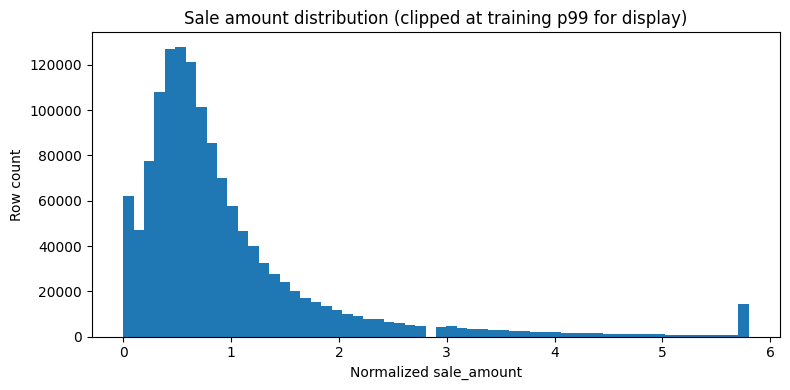

In [11]:
target = train_df["sale_amount"]
percentile_levels = [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
target_summary = pd.DataFrame({
    "metric": ["count", "mean", "median", "std", "zero_sales_pct"],
    "value": [
        target.count(),
        target.mean(),
        target.median(),
        target.std(),
        100 * target.eq(0).mean(),
    ],
})
percentiles = target.quantile(percentile_levels).rename("value").reset_index()
percentiles["metric"] = percentiles["index"].map(lambda q: f"p{int(q * 100):02d}")
percentiles = percentiles[["metric", "value"]]
display(pd.concat([target_summary, percentiles], ignore_index=True))

fig, ax = plt.subplots(figsize=(8, 4))
upper = target.quantile(0.99)
ax.hist(target.clip(upper=upper), bins=60)
ax.set_title("Sale amount distribution (clipped at training p99 for display)")
ax.set_xlabel("Normalized sale_amount")
ax.set_ylabel("Row count")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "target_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

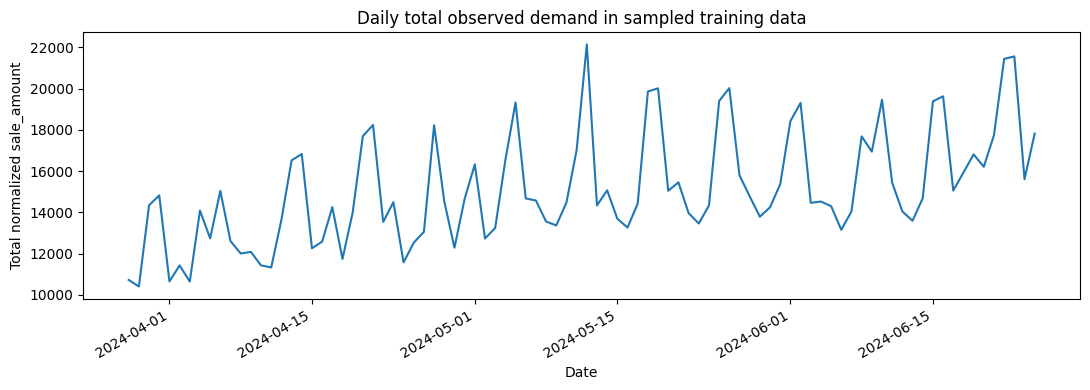

,day_of_week,sale_amount,weekday
0,0,0.941162,Mon
1,1,0.959717,Tue
2,2,0.905080,Wed
3,3,0.866141,Thu
4,4,0.925743,Fri
5,5,1.176959,Sat
6,6,1.199394,Sun


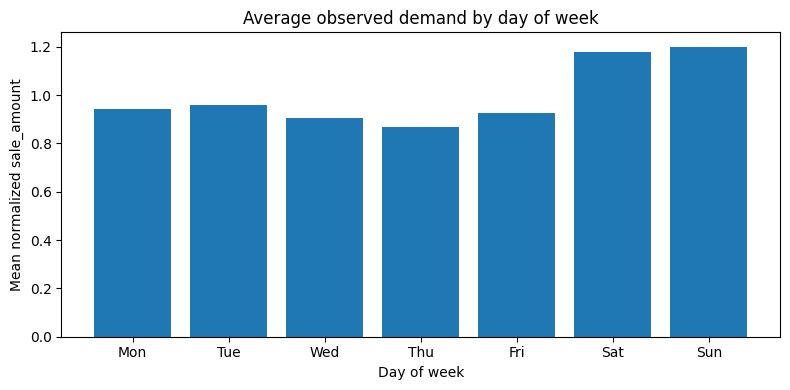

In [12]:
daily_demand = train_df.groupby("dt", as_index=False)["sale_amount"].sum()
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(daily_demand["dt"], daily_demand["sale_amount"])
ax.set_title("Daily total observed demand in sampled training data")
ax.set_xlabel("Date")
ax.set_ylabel("Total normalized sale_amount")
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "daily_total_demand.png", dpi=160, bbox_inches="tight")
plt.show()

train_df["day_of_week"] = train_df["dt"].dt.dayofweek.astype("int8")
weekday_names = {0: "Mon", 1: "Tue", 2: "Wed", 3: "Thu", 4: "Fri", 5: "Sat", 6: "Sun"}
weekday_demand = (
    train_df.groupby("day_of_week", as_index=False)["sale_amount"].mean()
    .assign(weekday=lambda d: d["day_of_week"].map(weekday_names))
)
display(weekday_demand)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(weekday_demand["weekday"], weekday_demand["sale_amount"])
ax.set_title("Average observed demand by day of week")
ax.set_xlabel("Day of week")
ax.set_ylabel("Mean normalized sale_amount")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "weekday_demand.png", dpi=160, bbox_inches="tight")
plt.show()

In [13]:
holiday_summary = (
    train_df.groupby("holiday_flag")["sale_amount"]
    .agg(observations="size", mean_sales="mean", median_sales="median")
    .reset_index()
)
display(holiday_summary)
print("Holiday differences are associations, not causal treatment effects.")

train_df["discount_pct"] = 1.0 - train_df["discount"]
print(f"discount range: {train_df['discount'].min():.4f} to {train_df['discount'].max():.4f}")
print(f"discount_pct range: {train_df['discount_pct'].min():.4f} to {train_df['discount_pct'].max():.4f}")

bins = [-np.inf, 0.0, 0.05, 0.10, 0.20, 0.30, np.inf]
labels = ["<=0%", "0-5%", "5-10%", "10-20%", "20-30%", ">30%"]
train_df["discount_bin"] = pd.cut(train_df["discount_pct"], bins=bins, labels=labels, right=True)
discount_summary = (
    train_df.groupby("discount_bin", observed=True)["sale_amount"]
    .agg(observations="size", mean_sales="mean", median_sales="median")
    .reset_index()
)
display(discount_summary)
print("Discount differences are descriptive associations only.")

,holiday_flag,observations,mean_sales,median_sales
0,0,892670,0.912661,0.6
1,1,469030,1.158467,0.8


Holiday differences are associations, not causal treatment effects.
discount range: 0.0000 to 1.0880
discount_pct range: -0.0880 to 1.0000


,discount_bin,observations,mean_sales,median_sales
0,<=0%,659253,0.827596,0.6
1,0-5%,88730,1.270285,0.9
2,5-10%,128593,0.831745,0.6
3,10-20%,257595,0.929546,0.7
4,20-30%,129080,1.124314,0.8
5,>30%,98449,2.115044,1.0


Discount differences are descriptive associations only.


In [14]:
series_profile = (
    train_df.groupby(SERIES_KEYS)["sale_amount"]
    .agg(
        zero_sales_ratio=lambda s: s.eq(0).mean(),
        mean_demand="mean",
        demand_std="std",
        observations="size",
    )
    .reset_index()
)
series_profile["intermittency_level"] = pd.cut(
    series_profile["zero_sales_ratio"],
    bins=[-np.inf, 0.20, 0.50, np.inf],
    labels=["low", "medium", "high"],
    right=False,
)

display(series_profile.describe(include="all"))
print(
    f"Highly intermittent series (zero_sales_ratio >= 0.50): "
    f"{series_profile['zero_sales_ratio'].ge(0.50).mean():.1%}"
)
print(
    "Stockout censoring means observed sale_amount can be lower than latent customer demand. "
    "This notebook forecasts observed sales; it does not recover censored latent demand."
)

,store_id,product_id,zero_sales_ratio,mean_demand,demand_std,observations,intermittency_level
count,15130.000000,15130.000000,15130.000000,15130.000000,15130.000000,15130.0,15130
unique,NaN,NaN,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,NaN,NaN,low
freq,NaN,NaN,NaN,NaN,NaN,NaN,14339
mean,410.456576,391.816259,0.045016,0.997327,0.531934,90.0,NaN
std,249.031881,264.765553,0.071271,1.191469,0.636332,0.0,NaN
min,0.000000,0.000000,0.000000,0.334444,0.101760,90.0,NaN
25%,195.000000,132.000000,0.000000,0.493472,0.270088,90.0,NaN
50%,401.000000,363.000000,0.022222,0.657000,0.367634,90.0,NaN
75%,601.750000,634.000000,0.055556,1.046333,0.577511,90.0,NaN


Highly intermittent series (zero_sales_ratio >= 0.50): 0.2%
Stockout censoring means observed sale_amount can be lower than latent customer demand. This notebook forecasts observed sales; it does not recover censored latent demand.


## 8. Time-series feature engineering

Features are created after sorting by `(store_id, product_id, dt)`. Sales lags and rolling statistics use only previous observations. The function deliberately leaves early-history `NaN`s visible; a later validation step removes rows only when sufficient history is required for model fitting.

In [15]:
CALENDAR_FEATURES = ["day_of_week", "day_of_month", "week_of_year", "month", "is_weekend"]
SALES_LAG_FEATURES = ["lag_1", "lag_2", "lag_3", "lag_7", "lag_14", "lag_28"]
ROLLING_FEATURES = [
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_mean_28",
    "rolling_std_7",
    "rolling_std_14",
    "rolling_std_28",
    "rolling_min_7",
    "rolling_max_7",
]
KNOWN_EXOGENOUS_FEATURES = ["discount", "discount_pct", "holiday_flag", "activity_flag"]


def create_features(df):
    out = df.copy()
    out = out.sort_values(SERIES_KEYS + ["dt"]).reset_index(drop=True)

    out["day_of_week"] = out["dt"].dt.dayofweek.astype("int8")
    out["day_of_month"] = out["dt"].dt.day.astype("int8")
    out["week_of_year"] = out["dt"].dt.isocalendar().week.astype("int16")
    out["month"] = out["dt"].dt.month.astype("int8")
    out["is_weekend"] = out["day_of_week"].isin([5, 6]).astype("int8")
    out["discount_pct"] = 1.0 - out["discount"]
    out["stockout_flag"] = out["stock_hour6_22_cnt"].gt(0).astype("int8")

    grouped = out.groupby(SERIES_KEYS, sort=False, observed=True)
    for lag in (1, 2, 3, 7, 14, 28):
        out[f"lag_{lag}"] = grouped["sale_amount"].shift(lag)

    for window in (7, 14, 28):
        out[f"rolling_mean_{window}"] = grouped["sale_amount"].transform(
            lambda s, w=window: s.shift(1).rolling(w, min_periods=w).mean()
        )
        out[f"rolling_std_{window}"] = grouped["sale_amount"].transform(
            lambda s, w=window: s.shift(1).rolling(w, min_periods=w).std()
        )

    out["rolling_min_7"] = grouped["sale_amount"].transform(
        lambda s: s.shift(1).rolling(7, min_periods=7).min()
    )
    out["rolling_max_7"] = grouped["sale_amount"].transform(
        lambda s: s.shift(1).rolling(7, min_periods=7).max()
    )
    out["stockout_lag_1"] = grouped["stockout_flag"].shift(1)
    out["stockout_lag_7"] = grouped["stockout_flag"].shift(7)
    return out


train_features_all = create_features(train_df)

### Prediction-time feature policy

Promotions and activities are treated as planned/known exogenous variables. If a real retailer does not know a future discount or activity schedule at forecast time, those variables must be removed or separately forecast.

For a fixed-origin horizon:

- recursive sales lags are updated with **model predictions**, never future actual sales
- `stockout_lag_1` is created for diagnostics but excluded from a 7-day fixed-origin model because it becomes unavailable after the first forecast step
- `stockout_lag_7` remains known for every step only when `FORECAST_HORIZON <= 7`

In [16]:
SAFE_STOCKOUT_MODEL_FEATURES = ["stockout_lag_7"] if FORECAST_HORIZON <= 7 else []

CORE_FEATURES = (
    CALENDAR_FEATURES
    + SALES_LAG_FEATURES
    + ROLLING_FEATURES
    + SAFE_STOCKOUT_MODEL_FEATURES
    + KNOWN_EXOGENOUS_FEATURES
    + ID_COLUMNS
)
ORACLE_FEATURES = CORE_FEATURES + WEATHER_COLUMNS

for feature_set_name, feature_set in {
    "Core Production-Like Model": CORE_FEATURES,
    "Oracle Weather Experiment": ORACLE_FEATURES,
}.items():
    assert "sale_amount" not in feature_set, f"Target leakage in {feature_set_name}."
    assert not set(SAME_DAY_LEAKAGE_COLUMNS).intersection(feature_set), (
        f"Same-day leakage columns found in {feature_set_name}: "
        f"{set(SAME_DAY_LEAKAGE_COLUMNS).intersection(feature_set)}"
    )

print(f"Core feature count: {len(CORE_FEATURES)}")
print(f"Oracle feature count: {len(ORACLE_FEATURES)}")
print(f"Stockout predictors safe for this horizon: {SAFE_STOCKOUT_MODEL_FEATURES}")

Core feature count: 31
Oracle feature count: 35
Stockout predictors safe for this horizon: ['stockout_lag_7']


## 9. Feature validation

The first 28 observations of each series do not have all required lag/rolling context. Those rows are removed **only for model fitting**, not from the raw source DataFrames.

In [17]:
MODEL_HISTORY_REQUIREMENTS = ["lag_28", "rolling_mean_28", "rolling_std_28"]

numeric_feature_columns = [
    c for c in (CALENDAR_FEATURES + SALES_LAG_FEATURES + ROLLING_FEATURES + ["stockout_lag_1", "stockout_lag_7"] + KNOWN_EXOGENOUS_FEATURES + WEATHER_COLUMNS)
    if c in train_features_all.columns
]

inf_counts = {
    c: int(np.isinf(pd.to_numeric(train_features_all[c], errors="coerce")).sum())
    for c in numeric_feature_columns
}
inf_counts = {k: v for k, v in inf_counts.items() if v > 0}
print("Infinite-value counts:", inf_counts if inf_counts else "none")
if inf_counts:
    raise ValueError(f"Infinite feature values detected: {inf_counts}")

nan_counts = train_features_all[CORE_FEATURES].isna().sum().sort_values(ascending=False)
display(nan_counts[nan_counts.gt(0)].rename("nan_count").reset_index(name="feature").head(30))

feature_duplicate_count = int(train_features_all.duplicated(ROW_KEY, keep=False).sum())
print(f"Feature-table duplicate key rows: {feature_duplicate_count:,}")
if feature_duplicate_count:
    raise ValueError("Feature engineering introduced duplicate row keys; stopping.")

train_features_ready = train_features_all.dropna(subset=MODEL_HISTORY_REQUIREMENTS).copy()
print(f"Raw training rows: {len(train_features_all):,}")
print(f"Feature-ready training rows: {len(train_features_ready):,}")
print(f"Rows removed for insufficient history: {len(train_features_all) - len(train_features_ready):,}")
print(f"Earliest raw date: {train_features_all['dt'].min().date()}")
print(f"Earliest feature-ready date: {train_features_ready['dt'].min().date()}")

display(train_features_ready[CORE_FEATURES].dtypes.rename("dtype").reset_index(name="feature"))

Infinite-value counts: none


,index,feature
0,lag_28,423640
1,rolling_mean_28,423640
2,rolling_std_28,423640
3,lag_14,211820
4,rolling_mean_14,211820
5,rolling_std_14,211820
6,rolling_std_7,105910
7,rolling_max_7,105910
8,rolling_min_7,105910
9,lag_7,105910


Feature-table duplicate key rows: 0


Raw training rows: 1,361,700
Feature-ready training rows: 938,060
Rows removed for insufficient history: 423,640
Earliest raw date: 2024-03-28
Earliest feature-ready date: 2024-04-25


,index,feature
0,day_of_week,int8
1,day_of_month,int8
2,week_of_year,int16
3,month,int8
4,is_weekend,int8
5,lag_1,float64
6,lag_2,float64
7,lag_3,float64
8,lag_7,float64
9,lag_14,float64


## 10. Forecast metrics

- **MAE:** mean absolute error
- **RMSE:** root mean squared error
- **WAPE:** `sum(abs(y - y_hat)) / sum(abs(y))`
- **Bias:** `sum(y_hat - y) / sum(abs(y))`

Bias is positive for net over-forecasting and negative for net under-forecasting. WAPE and Bias are reported as `NaN` when the denominator is zero. Each row includes the number of valid observations actually scored.

In [18]:
def calculate_metrics(y_true, y_pred, model_name, fold=None):
    y_true = pd.Series(y_true, dtype="float64")
    y_pred = pd.Series(y_pred, dtype="float64")
    valid = y_true.notna() & y_pred.notna() & np.isfinite(y_true) & np.isfinite(y_pred)
    y = y_true.loc[valid].to_numpy()
    p = y_pred.loc[valid].to_numpy()

    if len(y) == 0:
        return {
            "model": model_name,
            "fold": fold,
            "MAE": np.nan,
            "RMSE": np.nan,
            "WAPE": np.nan,
            "Bias": np.nan,
            "observations": 0,
        }

    denominator = np.abs(y).sum()
    return {
        "model": model_name,
        "fold": fold,
        "MAE": mean_absolute_error(y, p),
        "RMSE": np.sqrt(mean_squared_error(y, p)),
        "WAPE": np.nan if denominator == 0 else np.abs(y - p).sum() / denominator,
        "Bias": np.nan if denominator == 0 else (p - y).sum() / denominator,
        "observations": int(len(y)),
    }

## 11. Mandatory fixed-origin baselines

All four baselines are evaluated before LightGBM.

Within each 7-day validation window, predictions are generated recursively from information available at the fold origin. This prevents a subtle error where day-2 through day-7 predictions would otherwise use actual validation-period sales.

In [19]:
def forecast_baselines_fixed_origin(history_df, future_df):
    """Return four leakage-safe fixed-origin baseline forecasts aligned to future_df.index."""
    history_tail = (
        history_df.sort_values(SERIES_KEYS + ["dt"])
        .groupby(SERIES_KEYS, sort=False, observed=True)
        .tail(28)
    )
    history_map = {
        key: group["sale_amount"].astype(float).tolist()
        for key, group in history_tail.groupby(SERIES_KEYS, sort=False, observed=True)
    }

    records = []
    ordered_future = future_df.sort_values(SERIES_KEYS + ["dt"])
    for key, group in ordered_future.groupby(SERIES_KEYS, sort=False, observed=True):
        if not isinstance(key, tuple):
            key = (key,)
        base_history = list(history_map.get(key, []))
        states = {
            "Naive": list(base_history),
            "Seasonal Naive": list(base_history),
            "7-Day Moving Average": list(base_history),
            "28-Day Moving Average": list(base_history),
        }

        for row_index in group.index:
            naive = states["Naive"][-1] if len(states["Naive"]) >= 1 else np.nan
            seasonal = states["Seasonal Naive"][-7] if len(states["Seasonal Naive"]) >= 7 else np.nan
            ma7 = float(np.mean(states["7-Day Moving Average"][-7:])) if len(states["7-Day Moving Average"]) >= 7 else np.nan
            ma28 = float(np.mean(states["28-Day Moving Average"][-28:])) if len(states["28-Day Moving Average"]) >= 28 else np.nan

            predictions = {
                "Naive": naive,
                "Seasonal Naive": seasonal,
                "7-Day Moving Average": ma7,
                "28-Day Moving Average": ma28,
            }
            records.append({"_index": row_index, **predictions})

            for name, prediction in predictions.items():
                states[name].append(prediction)

    return pd.DataFrame(records).set_index("_index").reindex(future_df.index)

## 12. Rolling-origin backtesting

The folds are expanding-window, non-overlapping validation blocks from the tail of the training period. Every fold satisfies `training dates < validation dates`; random train/test splitting is never used.

In [20]:
def make_rolling_origin_folds(df, horizon, n_folds):
    unique_dates = np.array(sorted(pd.to_datetime(df["dt"].unique())))
    required_validation_days = horizon * n_folds
    if len(unique_dates) <= required_validation_days + 28:
        raise ValueError(
            f"Need more than {required_validation_days + 28} unique dates for "
            f"{n_folds} folds, horizon={horizon}, and 28-day lag history; found {len(unique_dates)}."
        )

    folds = []
    first_validation_start = len(unique_dates) - required_validation_days
    for fold_idx in range(n_folds):
        val_start_idx = first_validation_start + fold_idx * horizon
        val_end_idx = val_start_idx + horizon
        train_dates = unique_dates[:val_start_idx]
        validation_dates = unique_dates[val_start_idx:val_end_idx]
        folds.append({
            "fold": fold_idx + 1,
            "train_start": pd.Timestamp(train_dates[0]),
            "train_end": pd.Timestamp(train_dates[-1]),
            "validation_start": pd.Timestamp(validation_dates[0]),
            "validation_end": pd.Timestamp(validation_dates[-1]),
        })
    return folds


folds = make_rolling_origin_folds(train_df, FORECAST_HORIZON, N_BACKTEST_FOLDS)
fold_metadata = []
for fold in folds:
    train_mask = train_df["dt"].between(fold["train_start"], fold["train_end"])
    val_mask = train_df["dt"].between(fold["validation_start"], fold["validation_end"])
    fold_metadata.append({
        **fold,
        "train_rows": int(train_mask.sum()),
        "validation_rows": int(val_mask.sum()),
    })

fold_table = pd.DataFrame(fold_metadata)
display(fold_table)
assert (fold_table["train_end"] < fold_table["validation_start"]).all()

,fold,train_start,train_end,validation_start,validation_end,train_rows,validation_rows
0,1,2024-03-28,2024-06-04,2024-06-05,2024-06-11,1043970,105910
1,2,2024-03-28,2024-06-11,2024-06-12,2024-06-18,1149880,105910
2,3,2024-03-28,2024-06-18,2024-06-19,2024-06-25,1255790,105910


In [21]:
baseline_backtest_rows = []
for fold in folds:
    history = train_df.loc[train_df["dt"] <= fold["train_end"]]
    validation = train_df.loc[
        train_df["dt"].between(fold["validation_start"], fold["validation_end"])
    ]
    baseline_predictions = forecast_baselines_fixed_origin(history, validation)

    for model_name in baseline_predictions.columns:
        baseline_backtest_rows.append(
            calculate_metrics(
                validation["sale_amount"].reset_index(drop=True),
                baseline_predictions[model_name].reset_index(drop=True),
                model_name=model_name,
                fold=fold["fold"],
            )
        )

baseline_backtest_results = pd.DataFrame(baseline_backtest_rows)
display(baseline_backtest_results)
baseline_backtest_results.to_csv(TABLES_DIR / "baseline_backtest_results.csv", index=False)

metric_columns = ["MAE", "RMSE", "WAPE", "Bias"]
baseline_summary = baseline_backtest_results.groupby("model")[metric_columns].agg(["mean", "std"])
baseline_summary.columns = [f"{metric}_{stat}" for metric, stat in baseline_summary.columns]
baseline_summary = baseline_summary.reset_index().sort_values("WAPE_mean")
display(baseline_summary)

best_baseline_name = baseline_summary.iloc[0]["model"]
best_moving_name = (
    baseline_summary[baseline_summary["model"].isin(["7-Day Moving Average", "28-Day Moving Average"])]
    .sort_values("WAPE_mean")
    .iloc[0]["model"]
)
print(f"Best baseline by mean rolling-origin WAPE: {best_baseline_name}")
print(f"Best moving-average baseline by mean rolling-origin WAPE: {best_moving_name}")

,model,fold,MAE,RMSE,WAPE,Bias,observations
0,Naive,1,0.468597,0.868626,0.447146,-0.084305,105910
1,Seasonal Naive,1,0.456710,0.774708,0.435804,-0.008179,105910
2,7-Day Moving Average,1,0.381203,0.641788,0.363753,0.008154,105910
3,28-Day Moving Average,1,0.399502,0.691012,0.381214,0.004982,105910
4,Naive,2,0.466709,0.755930,0.440217,-0.038120,105910
5,Seasonal Naive,2,0.456824,0.762821,0.430894,-0.011513,105910
6,7-Day Moving Average,2,0.383744,0.623519,0.361962,0.024302,105910
7,28-Day Moving Average,2,0.398319,0.671121,0.375710,-0.005636,105910
8,Naive,3,0.506640,0.865748,0.421953,-0.123314,105910
9,Seasonal Naive,3,0.493171,0.831564,0.410735,-0.117035,105910


,model,MAE_mean,MAE_std,RMSE_mean,RMSE_std,WAPE_mean,WAPE_std,Bias_mean,Bias_std
1,7-Day Moving Average,0.397568,0.026174,0.661757,0.051230,0.360657,0.003916,-0.019940,0.063163
0,28-Day Moving Average,0.417698,0.032546,0.717067,0.063144,0.378698,0.002783,-0.040644,0.070033
3,Seasonal Naive,0.468902,0.021018,0.789698,0.036741,0.425811,0.013285,-0.045576,0.061908
2,Naive,0.480648,0.022529,0.830101,0.064250,0.436439,0.013015,-0.081913,0.042647


Best baseline by mean rolling-origin WAPE: 7-Day Moving Average
Best moving-average baseline by mean rolling-origin WAPE: 7-Day Moving Average


## 13. Global LightGBM

A single global model is trained across sampled store-product series. High-cardinality entity IDs are passed to LightGBM as pandas categorical variables rather than expanded into dense one-hot matrices.

Hyperparameters are intentionally conservative; this notebook does not run a large search. Early stopping uses a chronological slice from within the current training history only.

In [22]:
LGBM_PARAMS = {
    "objective": "regression_l1",
    "learning_rate": 0.05,
    "n_estimators": 1500,
    "num_leaves": 63,
    "min_child_samples": 100,
    "subsample": 0.80,
    "subsample_freq": 1,
    "colsample_bytree": 0.80,
    "reg_alpha": 0.10,
    "reg_lambda": 1.00,
    "random_state": RANDOM_STATE,
    "n_jobs": -1,
    "verbosity": -1,
}


def prepare_model_matrix(df, feature_columns, category_levels=None):
    X = df[feature_columns].copy()
    if category_levels is None:
        category_levels = {}
        for column in ID_COLUMNS:
            if column in X.columns:
                category_levels[column] = pd.Index(pd.unique(X[column].dropna()))

    for column, levels in category_levels.items():
        if column in X.columns:
            X[column] = pd.Categorical(X[column], categories=levels)
    return X, category_levels


def fit_lgbm_with_chronological_early_stopping(feature_df, feature_columns):
    dates = np.array(sorted(pd.to_datetime(feature_df["dt"].unique())))
    if len(dates) <= EARLY_STOP_DAYS:
        raise ValueError("Not enough dates for chronological early stopping.")

    es_dates = dates[-EARLY_STOP_DAYS:]
    fit_df = feature_df.loc[feature_df["dt"] < es_dates[0]]
    es_df = feature_df.loc[feature_df["dt"].isin(es_dates)]
    if fit_df.empty or es_df.empty:
        raise ValueError("Chronological early-stopping split produced an empty partition.")

    X_fit, category_levels = prepare_model_matrix(fit_df, feature_columns)
    X_es, _ = prepare_model_matrix(es_df, feature_columns, category_levels)
    y_fit = fit_df["sale_amount"].astype(float)
    y_es = es_df["sale_amount"].astype(float)

    model = lgb.LGBMRegressor(**LGBM_PARAMS)
    categorical_features = [c for c in ID_COLUMNS if c in feature_columns]
    model.fit(
        X_fit,
        y_fit,
        eval_set=[(X_es, y_es)],
        eval_metric="l1",
        categorical_feature=categorical_features,
        callbacks=[
            lgb.early_stopping(EARLY_STOPPING_ROUNDS, verbose=False),
            lgb.log_evaluation(period=0),
        ],
    )
    best_iteration = int(model.best_iteration_ or LGBM_PARAMS["n_estimators"])
    return model, category_levels, best_iteration


def refit_lgbm_all(feature_df, feature_columns, n_estimators):
    params = dict(LGBM_PARAMS)
    params["n_estimators"] = max(1, int(n_estimators))
    X, category_levels = prepare_model_matrix(feature_df, feature_columns)
    model = lgb.LGBMRegressor(**params)
    model.fit(
        X,
        feature_df["sale_amount"].astype(float),
        categorical_feature=[c for c in ID_COLUMNS if c in feature_columns],
        callbacks=[lgb.log_evaluation(period=0)],
    )
    return model, category_levels

### Recursive fixed-origin LightGBM prediction

For each future day, sales-history features are recomputed from the last known history plus prior **predictions** from the same forecast window. Actual future `sale_amount` is never read into the model state.

Future stockout state is not assumed known. The function still calculates `stockout_lag_1` for diagnostics; after the first step it becomes missing. The core model feature policy therefore uses only stockout lags that remain origin-safe for the configured horizon.

In [23]:
def _lag(values, n):
    return float(values[-n]) if len(values) >= n and pd.notna(values[-n]) else np.nan


def _rolling_stat(values, window, statistic):
    if len(values) < window:
        return np.nan
    sub = values[-window:]
    if any(x is None or x != x for x in sub):
        return np.nan
    if statistic == "mean":
        return float(sum(sub) / window)
    if statistic == "min":
        return float(min(sub))
    if statistic == "max":
        return float(max(sub))
    if statistic == "std":
        if window < 2:
            return 0.0
        m = sum(sub) / window
        var = sum((x - m) ** 2 for x in sub) / (window - 1)
        return float(var ** 0.5)
    raise ValueError(f"Unknown statistic: {statistic}")


def recursive_lgbm_forecast(model, category_levels, history_df, future_df, feature_columns):
    assert "sale_amount" not in feature_columns
    assert not set(SAME_DAY_LEAKAGE_COLUMNS).intersection(feature_columns)

    history_sorted = history_df.sort_values(SERIES_KEYS + ["dt"])
    sales_tail = history_sorted.groupby(SERIES_KEYS, sort=False, observed=True).tail(28)
    stock_tail = history_sorted.groupby(SERIES_KEYS, sort=False, observed=True).tail(7).copy()
    stock_tail["_stockout"] = stock_tail["stock_hour6_22_cnt"].gt(0).astype(float)

    sales_state = {
        key: group["sale_amount"].astype(float).tolist()
        for key, group in sales_tail.groupby(SERIES_KEYS, sort=False, observed=True)
    }
    stock_state = {
        key: group["_stockout"].astype(float).tolist()
        for key, group in stock_tail.groupby(SERIES_KEYS, sort=False, observed=True)
    }

    output_parts = []
    ordered_future = future_df.sort_values(["dt"] + SERIES_KEYS)
    for forecast_date, day in ordered_future.groupby("dt", sort=True):
        day = day.copy()
        day["day_of_week"] = forecast_date.dayofweek
        day["day_of_month"] = forecast_date.day
        day["week_of_year"] = int(forecast_date.isocalendar().week)
        day["month"] = forecast_date.month
        day["is_weekend"] = int(forecast_date.dayofweek >= 5)
        day["discount_pct"] = 1.0 - day["discount"]

        keys = list(zip(day["store_id"], day["product_id"]))
        lag_features = {name: [] for name in SALES_LAG_FEATURES}
        rolling_values = {name: [] for name in ROLLING_FEATURES}
        stockout_lag_1 = []
        stockout_lag_7 = []
        recent_stockout_7d = []

        for key in keys:
            sales = sales_state.get(key, [])
            stocks = stock_state.get(key, [])
            for lag in (1, 2, 3, 7, 14, 28):
                lag_features[f"lag_{lag}"].append(_lag(sales, lag))
            for window in (7, 14, 28):
                rolling_values[f"rolling_mean_{window}"].append(_rolling_stat(sales, window, "mean"))
                rolling_values[f"rolling_std_{window}"].append(_rolling_stat(sales, window, "std"))
            rolling_values["rolling_min_7"].append(_rolling_stat(sales, 7, "min"))
            rolling_values["rolling_max_7"].append(_rolling_stat(sales, 7, "max"))
            stockout_lag_1.append(_lag(stocks, 1))
            stockout_lag_7.append(_lag(stocks, 7))
            finite_recent = [x for x in stocks[-7:] if pd.notna(x)]
            recent_stockout_7d.append(int(any(x > 0 for x in finite_recent)) if finite_recent else np.nan)

        for name, values in lag_features.items():
            day[name] = values
        for name, values in rolling_values.items():
            day[name] = values
        day["stockout_lag_1"] = stockout_lag_1
        day["stockout_lag_7"] = stockout_lag_7
        day["recent_stockout_7d"] = recent_stockout_7d

        X_day, _ = prepare_model_matrix(day, feature_columns, category_levels)
        prediction = model.predict(X_day)
        prediction = np.clip(np.asarray(prediction, dtype="float64"), a_min=0.0, a_max=None)
        day["prediction"] = prediction
        output_parts.append(day)

        for key, pred in zip(keys, prediction):
            sales_state.setdefault(key, []).append(float(pred))
            stock_state.setdefault(key, []).append(np.nan)  # future actual stockout is intentionally unavailable

    result = pd.concat(output_parts, axis=0).sort_index()
    return result

## 14. LightGBM rolling backtests

Both LightGBM experiments use the same folds as the baselines. Model training is restricted to rows strictly before each validation window. The oracle model differs only by the inclusion of realized weather variables.

In [24]:
lgbm_backtest_rows = []
best_iterations = {"LightGBM": [], "Oracle Weather Experiment": []}

for fold in folds:
    fold_train_features = train_features_ready.loc[
        train_features_ready["dt"] <= fold["train_end"]
    ]
    history_raw = train_df.loc[train_df["dt"] <= fold["train_end"]]
    validation_raw = train_df.loc[
        train_df["dt"].between(fold["validation_start"], fold["validation_end"])
    ]

    experiments = [
        ("LightGBM", CORE_FEATURES),
        ("Oracle Weather Experiment", ORACLE_FEATURES),
    ]

    for experiment_name, feature_columns in experiments:
        model, category_levels, best_iteration = fit_lgbm_with_chronological_early_stopping(
            fold_train_features, feature_columns
        )
        best_iterations[experiment_name].append(best_iteration)
        predicted = recursive_lgbm_forecast(
            model,
            category_levels,
            history_raw,
            validation_raw,
            feature_columns,
        )
        lgbm_backtest_rows.append(
            calculate_metrics(
                predicted["sale_amount"].reset_index(drop=True),
                predicted["prediction"].reset_index(drop=True),
                model_name=experiment_name,
                fold=fold["fold"],
            )
        )
        print(
            f"Fold {fold['fold']} | {experiment_name} | "
            f"best_iteration={best_iteration}"
        )

lgbm_backtest_results = pd.DataFrame(lgbm_backtest_rows)
display(lgbm_backtest_results)

all_backtest_results = pd.concat(
    [baseline_backtest_results, lgbm_backtest_results], ignore_index=True
)
backtest_summary = all_backtest_results.groupby("model")[metric_columns].agg(["mean", "std"])
backtest_summary.columns = [f"{metric}_{stat}" for metric, stat in backtest_summary.columns]
backtest_summary = backtest_summary.reset_index().sort_values("WAPE_mean")
display(backtest_summary)

seasonal_bt_wape = backtest_summary.loc[
    backtest_summary["model"].eq("Seasonal Naive"), "WAPE_mean"
].iloc[0]
lgbm_bt_wape = backtest_summary.loc[
    backtest_summary["model"].eq("LightGBM"), "WAPE_mean"
].iloc[0]
if seasonal_bt_wape > 0:
    complexity_gain_pct = 100 * (seasonal_bt_wape - lgbm_bt_wape) / seasonal_bt_wape
    print(f"Core LightGBM relative WAPE change vs Seasonal Naive: {complexity_gain_pct:+.2f}%")
else:
    print("Seasonal Naive WAPE is zero; relative improvement is undefined.")

D:\DemandPulse\DemandPulse\.venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 1 | LightGBM | best_iteration=138


D:\DemandPulse\DemandPulse\.venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 1 | Oracle Weather Experiment | best_iteration=121


D:\DemandPulse\DemandPulse\.venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 2 | LightGBM | best_iteration=158


... (5 outputs left out)

Fold 3 | Oracle Weather Experiment | best_iteration=369


,model,fold,MAE,RMSE,WAPE,Bias,observations
0,LightGBM,1,0.367080,0.623644,0.350277,0.025541,105910
1,Oracle Weather Experiment,1,0.366450,0.627885,0.349676,0.020343,105910
2,LightGBM,2,0.345729,0.577352,0.326105,0.012072,105910
3,Oracle Weather Experiment,2,0.348434,0.581222,0.328656,0.005857,105910
4,LightGBM,3,0.401679,0.696669,0.334536,-0.104413,105910
5,Oracle Weather Experiment,3,0.403674,0.701942,0.336198,-0.110235,105910


,model,MAE_mean,MAE_std,RMSE_mean,RMSE_std,WAPE_mean,WAPE_std,Bias_mean,Bias_std
2,LightGBM,0.371496,0.028235,0.632555,0.060155,0.336973,0.012269,-0.022267,0.071459
4,Oracle Weather Experiment,0.372853,0.028171,0.637017,0.060876,0.338177,0.010648,-0.028012,0.071575
1,7-Day Moving Average,0.397568,0.026174,0.661757,0.051230,0.360657,0.003916,-0.019940,0.063163
0,28-Day Moving Average,0.417698,0.032546,0.717067,0.063144,0.378698,0.002783,-0.040644,0.070033
5,Seasonal Naive,0.468902,0.021018,0.789698,0.036741,0.425811,0.013285,-0.045576,0.061908
3,Naive,0.480648,0.022529,0.830101,0.064250,0.436439,0.013015,-0.081913,0.042647


Core LightGBM relative WAPE change vs Seasonal Naive: +20.86%


## 15. Final model training

The official `eval` split has not been used for parameter selection. The final tree count is selected using chronological early stopping **inside `train`**, then the selected model is refit on all feature-ready training rows.

In [25]:
# Determine tree counts from training only.
core_es_model, _, core_best_iteration = fit_lgbm_with_chronological_early_stopping(
    train_features_ready, CORE_FEATURES
)
oracle_es_model, _, oracle_best_iteration = fit_lgbm_with_chronological_early_stopping(
    train_features_ready, ORACLE_FEATURES
)

final_core_model, final_core_categories = refit_lgbm_all(
    train_features_ready, CORE_FEATURES, core_best_iteration
)
final_oracle_model, final_oracle_categories = refit_lgbm_all(
    train_features_ready, ORACLE_FEATURES, oracle_best_iteration
)

print(f"Final core n_estimators: {core_best_iteration}")
print(f"Final oracle n_estimators: {oracle_best_iteration}")

# Native LightGBM artifact.
final_core_model.booster_.save_model(str(MODELS_DIR / "demandpulse_lgbm.txt"))
print(f"Saved model: {MODELS_DIR / 'demandpulse_lgbm.txt'}")

D:\DemandPulse\DemandPulse\.venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


D:\DemandPulse\DemandPulse\.venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Final core n_estimators: 1161
Final oracle n_estimators: 949


Saved model: models\demandpulse_lgbm.txt


## 16. Feature importance

Gain-based importance is descriptive of the fitted model, not causal importance. SHAP is deliberately omitted from the default run because it can be expensive at this scale; if added later, it should be run on a clearly stated manageable sample rather than the entire dataset.

,feature,gain_importance,split_importance,gain_share
0,rolling_mean_7,2.542249e+06,735,0.309221
1,product_id,1.499514e+06,23938,0.182390
2,store_id,1.307936e+06,30265,0.159088
3,rolling_mean_14,1.034822e+06,427,0.125868
4,rolling_mean_28,4.471502e+05,374,0.054388
5,third_category_id,2.803263e+05,4526,0.034097
6,day_of_week,1.897050e+05,1096,0.023074
7,discount,1.685607e+05,1314,0.020503
8,lag_1,1.371952e+05,1045,0.016687
9,day_of_month,1.038931e+05,1774,0.012637


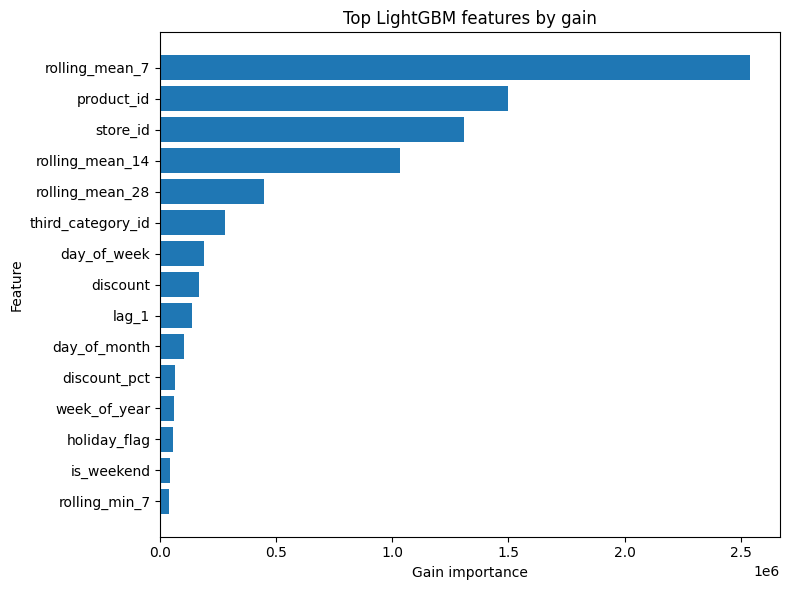

In [26]:
feature_importance = pd.DataFrame({
    "feature": final_core_model.booster_.feature_name(),
    "gain_importance": final_core_model.booster_.feature_importance(importance_type="gain"),
    "split_importance": final_core_model.booster_.feature_importance(importance_type="split"),
})
feature_importance["gain_share"] = (
    feature_importance["gain_importance"] / feature_importance["gain_importance"].sum()
    if feature_importance["gain_importance"].sum() > 0
    else np.nan
)
feature_importance = feature_importance.sort_values("gain_importance", ascending=False).reset_index(drop=True)
display(feature_importance.head(20))
feature_importance.to_csv(TABLES_DIR / "feature_importance.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 6))
top_imp = feature_importance.head(15).sort_values("gain_importance")
ax.barh(top_imp["feature"], top_imp["gain_importance"])
ax.set_title("Top LightGBM features by gain")
ax.set_xlabel("Gain importance")
ax.set_ylabel("Feature")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "feature_importance.png", dpi=160, bbox_inches="tight")
plt.show()

## 17. Final official evaluation on the untouched Hugging Face `eval` split

Workflow:

`training data → rolling backtesting → model selection → final training → official eval split`

The official evaluation uses a fixed forecast origin at the end of `train`. If the source split ceases to be strictly later than training data, execution stops rather than silently changing the evaluation design.

In [27]:
if not STRICT_TEMPORAL_HOLDOUT:
    raise ValueError(
        "Official eval is not strictly later than train in this runtime. "
        f"max(train)={train_max_date}, min(eval)={eval_min_date}. "
        "A fixed-origin holdout evaluation would be invalid without redesigning the split."
    )

official_baselines = forecast_baselines_fixed_origin(train_df, eval_df)
official_core = recursive_lgbm_forecast(
    final_core_model,
    final_core_categories,
    train_df,
    eval_df,
    CORE_FEATURES,
)
official_oracle = recursive_lgbm_forecast(
    final_oracle_model,
    final_oracle_categories,
    train_df,
    eval_df,
    ORACLE_FEATURES,
)

best_moving_column = best_moving_name
final_metric_rows = [
    calculate_metrics(eval_df["sale_amount"], official_baselines["Naive"], "Naive"),
    calculate_metrics(eval_df["sale_amount"], official_baselines["Seasonal Naive"], "Seasonal Naive"),
    calculate_metrics(eval_df["sale_amount"], official_baselines[best_moving_column], best_moving_column),
    calculate_metrics(official_core["sale_amount"], official_core["prediction"], "LightGBM"),
    calculate_metrics(official_oracle["sale_amount"], official_oracle["prediction"], "Oracle Weather Experiment"),
]
final_model_comparison = pd.DataFrame(final_metric_rows).drop(columns="fold")
final_model_comparison = final_model_comparison.sort_values("WAPE").reset_index(drop=True)
display(final_model_comparison)
final_model_comparison.to_csv(TABLES_DIR / "final_model_comparison.csv", index=False)

,model,MAE,RMSE,WAPE,Bias,observations
0,LightGBM,0.384824,0.661466,0.321471,-0.026370,105910
1,Oracle Weather Experiment,0.385942,0.667294,0.322406,-0.053604,105910
2,7-Day Moving Average,0.428330,0.716401,0.357816,0.015271,105910
3,Seasonal Naive,0.498713,0.840183,0.416611,0.003034,105910
4,Naive,0.511428,0.861475,0.427233,-0.016274,105910


## 18. Error analysis

The core LightGBM forecast is analyzed against Seasonal Naive across entity, calendar, promotion, stockout-history, demand-level, and intermittency slices. These are diagnostic associations; they are not causal decompositions.

In [28]:
eval_results = official_core.copy()
eval_results = eval_results.rename(columns={"prediction": "lightgbm_prediction"})
eval_results["seasonal_naive_prediction"] = official_baselines["Seasonal Naive"].reindex(eval_results.index)
eval_results["error"] = eval_results["lightgbm_prediction"] - eval_results["sale_amount"]
eval_results["absolute_error"] = eval_results["error"].abs()
eval_results["percentage_error"] = np.where(
    eval_results["sale_amount"].ne(0),
    eval_results["error"] / eval_results["sale_amount"],
    np.nan,
)

# Attach training-derived series characteristics without using eval targets.
profile_for_join = series_profile.copy()
profile_for_join["demand_level"] = pd.qcut(
    profile_for_join["mean_demand"].rank(method="first"),
    q=3,
    labels=["low", "medium", "high"],
)
eval_results = eval_results.merge(profile_for_join, on=SERIES_KEYS, how="left", validate="many_to_one")


def group_error_metrics(df, group_column, group_label):
    rows = []
    for value, group in df.groupby(group_column, dropna=False, observed=True):
        metrics = calculate_metrics(
            group["sale_amount"],
            group["lightgbm_prediction"],
            model_name="LightGBM",
        )
        rows.append({
            "segment_type": group_label,
            "segment_value": str(value),
            "MAE": metrics["MAE"],
            "RMSE": metrics["RMSE"],
            "WAPE": metrics["WAPE"],
            "Bias": metrics["Bias"],
            "observations": metrics["observations"],
        })
    return pd.DataFrame(rows)


segment_tables = []
for column, label in [
    ("store_id", "store_id"),
    ("product_id", "product_id"),
    ("city_id", "city_id"),
    ("third_category_id", "third_category_id"),
    ("holiday_flag", "holiday"),
    ("activity_flag", "promotion_activity"),
    ("recent_stockout_7d", "recent_stockout_history"),
    ("demand_level", "demand_level"),
    ("intermittency_level", "intermittency_level"),
]:
    segment_tables.append(group_error_metrics(eval_results, column, label))

segment_error_analysis = pd.concat(segment_tables, ignore_index=True)
segment_error_analysis.to_csv(TABLES_DIR / "segment_error_analysis.csv", index=False)

display(
    segment_error_analysis[
        segment_error_analysis["segment_type"].isin(
            ["city_id", "holiday", "promotion_activity", "recent_stockout_history", "demand_level", "intermittency_level"]
        )
    ].sort_values(["segment_type", "WAPE"])
)

,segment_type,segment_value,MAE,RMSE,WAPE,Bias,observations
1572,city_id,11,0.393073,0.766599,0.249438,-0.009402,4144
1578,city_id,17,0.453656,0.912799,0.254399,-0.085774,567
1562,city_id,1,0.291065,0.484352,0.267979,-0.024401,938
1571,city_id,10,0.578805,1.191684,0.288230,-0.018476,714
1565,city_id,4,0.513096,1.008003,0.297995,-0.069872,2366
1574,city_id,13,0.323625,0.576988,0.304916,-0.030340,4837
1561,city_id,0,0.374447,0.622362,0.309506,-0.028232,53746
1577,city_id,16,0.383651,0.622922,0.316113,-0.040449,9912
1567,city_id,6,0.424816,0.764832,0.319719,0.001274,5222
1569,city_id,8,0.296744,0.416063,0.351724,-0.090562,133


In [29]:
# Where does LightGBM lose to Seasonal Naive at the store-product level?
series_comparison_rows = []
for key, group in eval_results.groupby(SERIES_KEYS, observed=True):
    lgbm_metrics = calculate_metrics(group["sale_amount"], group["lightgbm_prediction"], "LightGBM")
    seasonal_metrics = calculate_metrics(group["sale_amount"], group["seasonal_naive_prediction"], "Seasonal Naive")
    series_comparison_rows.append({
        "store_id": key[0],
        "product_id": key[1],
        "observations": lgbm_metrics["observations"],
        "lightgbm_mae": lgbm_metrics["MAE"],
        "seasonal_naive_mae": seasonal_metrics["MAE"],
        "mae_difference_lgbm_minus_seasonal": lgbm_metrics["MAE"] - seasonal_metrics["MAE"],
    })

series_model_comparison = pd.DataFrame(series_comparison_rows)
worse_than_seasonal = series_model_comparison[
    series_model_comparison["mae_difference_lgbm_minus_seasonal"] > 0
].sort_values("mae_difference_lgbm_minus_seasonal", ascending=False)

print(
    f"Series where LightGBM MAE is worse than Seasonal Naive: "
    f"{len(worse_than_seasonal):,} / {len(series_model_comparison):,} "
    f"({len(worse_than_seasonal) / len(series_model_comparison):.1%})"
)
display(worse_than_seasonal.head(20))

Series where LightGBM MAE is worse than Seasonal Naive: 3,097 / 15,130 (20.5%)


,store_id,product_id,observations,lightgbm_mae,seasonal_naive_mae,mae_difference_lgbm_minus_seasonal
14504,852,267,7,4.341932,3.071429,1.270504
12348,675,191,7,2.125862,0.857143,1.268719
11680,627,589,7,4.627006,3.414286,1.212720
12234,669,267,7,4.676683,3.557143,1.119541
7898,419,92,7,1.550148,0.485714,1.064434
14349,843,300,7,2.724318,1.692857,1.031460
470,23,267,7,4.852308,3.871429,0.980880
8332,440,191,7,1.703510,0.728571,0.974939
12606,697,589,7,1.851374,0.900000,0.951374
11757,632,267,7,3.488351,2.542857,0.945494


## 19. Model failure examples

`error = prediction - actual`, so positive errors are over-forecasts and negative errors are under-forecasts. The lag values shown below are the **origin-safe values actually available to the recursive forecasting routine**, not reconstructed from future actual sales.

In [30]:
failure_columns = [
    "store_id",
    "product_id",
    "dt",
    "sale_amount",
    "lightgbm_prediction",
    "lag_1",
    "lag_7",
    "discount",
    "holiday_flag",
    "recent_stockout_7d",
    "error",
    "absolute_error",
]

largest_errors = eval_results.nlargest(10, "absolute_error")[failure_columns]
strong_overforecasts = eval_results.nlargest(10, "error")[failure_columns]
strong_underforecasts = eval_results.nsmallest(10, "error")[failure_columns]

print("10 largest absolute errors")
display(largest_errors)
print("Strong over-forecasts")
display(strong_overforecasts)
print("Strong under-forecasts")
display(strong_underforecasts)

print(
    "Plausible, non-exclusive explanations include abrupt demand changes, promotion effects, "
    "intermittent demand, stockout censoring in the historical signal, and imperfectly transferable "
    "patterns across entities. These diagnostics do not establish causal explanations."
)

10 largest absolute errors

,store_id,product_id,dt,sale_amount,lightgbm_prediction,lag_1,lag_7,discount,holiday_flag,recent_stockout_7d,error,absolute_error
72407,23,267,2024-07-02,42.7,26.270444,26.264241,32.3,0.000,0,0,-16.429556,16.429556
70087,681,267,2024-06-29,13.2,29.122409,27.499631,26.4,0.000,1,1,15.922409,15.922409
68771,514,267,2024-06-29,12.5,27.585644,27.308387,31.2,0.000,1,1,15.085644,15.085644
93470,133,267,2024-07-02,4.3,19.251978,19.906717,19.2,0.000,0,0,14.951978,14.951978
84582,432,267,2024-06-27,10.3,24.631223,24.259824,21.9,0.000,0,1,14.331223,14.331223
83378,391,267,2024-06-27,12.8,26.952370,27.208514,25.0,0.000,0,1,14.152370,14.152370
94998,737,267,2024-06-27,7.8,21.805345,22.506160,19.0,0.000,0,0,14.005345,14.005345
63286,866,267,2024-07-02,39.0,25.916298,25.970738,29.2,0.000,0,0,-13.083702,13.083702
89120,627,589,2024-06-29,40.6,27.976195,27.783308,35.3,0.000,1,1,-12.623805,12.623805
33639,417,756,2024-06-30,32.2,20.177230,21.484869,23.8,0.992,1,1,-12.022770,12.022770


Strong over-forecasts


,store_id,product_id,dt,sale_amount,lightgbm_prediction,lag_1,lag_7,discount,holiday_flag,recent_stockout_7d,error,absolute_error
70087,681,267,2024-06-29,13.2,29.122409,27.499631,26.4,0.0,1,1,15.922409,15.922409
68771,514,267,2024-06-29,12.5,27.585644,27.308387,31.2,0.0,1,1,15.085644,15.085644
93470,133,267,2024-07-02,4.3,19.251978,19.906717,19.2,0.0,0,0,14.951978,14.951978
84582,432,267,2024-06-27,10.3,24.631223,24.259824,21.9,0.0,0,1,14.331223,14.331223
83378,391,267,2024-06-27,12.8,26.952370,27.208514,25.0,0.0,0,1,14.152370,14.152370
94998,737,267,2024-06-27,7.8,21.805345,22.506160,19.0,0.0,0,0,14.005345,14.005345
68770,514,267,2024-06-28,15.6,27.308387,25.905283,29.1,0.0,0,1,11.708387,11.708387
41124,555,300,2024-07-02,0.5,11.773168,10.218712,17.6,1.0,0,0,11.273168,11.273168
70084,681,267,2024-06-26,13.5,23.514255,17.600000,26.5,0.0,0,1,10.014255,10.014255
83382,391,267,2024-07-01,17.1,26.352846,29.933188,25.8,0.0,0,1,9.252846,9.252846


Strong under-forecasts


,store_id,product_id,dt,sale_amount,lightgbm_prediction,lag_1,lag_7,discount,holiday_flag,recent_stockout_7d,error,absolute_error
72407,23,267,2024-07-02,42.7,26.270444,26.264241,32.3,0.000,0,0,-16.429556,16.429556
63286,866,267,2024-07-02,39.0,25.916298,25.970738,29.2,0.000,0,0,-13.083702,13.083702
89120,627,589,2024-06-29,40.6,27.976195,27.783308,35.3,0.000,1,1,-12.623805,12.623805
33639,417,756,2024-06-30,32.2,20.177230,21.484869,23.8,0.992,1,1,-12.022770,12.022770
63629,881,267,2024-07-02,34.6,23.015637,22.937265,27.2,0.000,0,0,-11.584363,11.584363
74911,608,267,2024-06-30,43.4,32.193946,32.233872,33.8,0.000,1,1,-11.206054,11.206054
72519,101,267,2024-07-02,34.3,23.595089,23.081729,27.4,0.000,0,1,-10.704911,10.704911
105790,896,267,2024-07-02,36.4,25.842243,25.949326,29.1,0.000,0,0,-10.557757,10.557757
62887,852,267,2024-07-02,36.9,27.089498,27.798835,37.0,0.000,0,0,-9.810502,9.810502
76236,669,267,2024-07-02,38.0,28.223371,28.482384,34.3,0.000,0,0,-9.776629,9.776629


Plausible, non-exclusive explanations include abrupt demand changes, promotion effects, intermittent demand, stockout censoring in the historical signal, and imperfectly transferable patterns across entities. These diagnostics do not establish causal explanations.


## 20. Output artifact audit

Required artifacts are written under `reports/` and `models/`. This cell verifies that the expected files exist before the notebook concludes.

In [31]:
required_artifacts = [
    TABLES_DIR / "baseline_backtest_results.csv",
    TABLES_DIR / "final_model_comparison.csv",
    TABLES_DIR / "segment_error_analysis.csv",
    TABLES_DIR / "feature_importance.csv",
    MODELS_DIR / "demandpulse_lgbm.txt",
]

artifact_audit = pd.DataFrame({
    "artifact": [str(path) for path in required_artifacts],
    "exists": [path.exists() for path in required_artifacts],
    "size_bytes": [path.stat().st_size if path.exists() else np.nan for path in required_artifacts],
})
display(artifact_audit)
assert artifact_audit["exists"].all(), "One or more required output artifacts were not created."

,artifact,exists,size_bytes
0,reports\tables\baseline_backtest_results.csv,True,1295
1,reports\tables\final_model_comparison.csv,True,548
2,reports\tables\segment_error_analysis.csv,True,176377
3,reports\tables\feature_importance.csv,True,1819
4,models\demandpulse_lgbm.txt,True,13951166


# Limitations

- **Normalized target:** `sale_amount` is globally normalized by the dataset provider, so error values are not directly interpretable as physical units sold.
- **Censored demand:** stockouts can suppress observed sales below latent customer demand; this notebook forecasts observed sales rather than recovering latent demand.
- **Short per-series history:** the dataset provides a relatively short history per store-product series, limiting long-seasonality inference.
- **Observational promotions:** discount, holiday, and activity associations are not causal effects.
- **No causal conclusions:** the workflow is predictive only.
- **Weather realism:** the core model excludes realized same-day future weather; the oracle experiment is an upper-bound diagnostic and would require forecasted weather in production.
- **Sampling:** when `SERIES_SAMPLE_PERCENT < 100`, results describe the deterministic sampled series, not necessarily the full 50K-series benchmark.
- **External generalization:** performance on FreshRetailNet-50K may not transfer to unrelated retailers, assortments, countries, replenishment policies, or demand regimes.
- **Fixed-origin stockout knowledge:** future stockout status is not assumed known. Stockout lags are included only when they remain available at the forecast origin for the configured horizon.

# Findings

The next cell generates the final scientific interpretation directly from executed results. It deliberately avoids promotional adjectives and reports quantitative evidence where available.

In [32]:
def _metric_value(table, model, metric):
    match = table.loc[table["model"].eq(model), metric]
    return float(match.iloc[0]) if len(match) else np.nan


best_baseline_bt_row = baseline_summary.sort_values("WAPE_mean").iloc[0]
best_baseline_bt = best_baseline_bt_row["model"]
best_baseline_bt_wape = float(best_baseline_bt_row["WAPE_mean"])

final_lgbm_wape = _metric_value(final_model_comparison, "LightGBM", "WAPE")
final_seasonal_wape = _metric_value(final_model_comparison, "Seasonal Naive", "WAPE")
final_lgbm_bias = _metric_value(final_model_comparison, "LightGBM", "Bias")

if np.isfinite(final_seasonal_wape) and final_seasonal_wape > 0 and np.isfinite(final_lgbm_wape):
    final_relative_improvement = 100 * (final_seasonal_wape - final_lgbm_wape) / final_seasonal_wape
    comparison_sentence = (
        f"On the official eval split, LightGBM changed WAPE by {final_relative_improvement:+.2f}% "
        f"relative to Seasonal Naive ({final_lgbm_wape:.4f} vs {final_seasonal_wape:.4f})."
    )
else:
    comparison_sentence = "A relative LightGBM-vs-seasonal WAPE improvement is undefined because the denominator is zero or unavailable."

intermittency_slice = segment_error_analysis[
    segment_error_analysis["segment_type"].eq("intermittency_level")
].dropna(subset=["WAPE"])
if not intermittency_slice.empty:
    hardest_intermittency = intermittency_slice.sort_values("WAPE", ascending=False).iloc[0]
    intermittent_sentence = (
        f"The highest-WAPE intermittency slice was `{hardest_intermittency['segment_value']}` "
        f"with WAPE {hardest_intermittency['WAPE']:.4f}."
    )
else:
    intermittent_sentence = "Intermittency-slice WAPE could not be computed."

hardest_demand_slice = segment_error_analysis[
    segment_error_analysis["segment_type"].eq("demand_level")
].dropna(subset=["WAPE"])
if not hardest_demand_slice.empty:
    hardest_demand = hardest_demand_slice.sort_values("WAPE", ascending=False).iloc[0]
    demand_sentence = (
        f"The highest-WAPE demand-level slice was `{hardest_demand['segment_value']}` "
        f"with WAPE {hardest_demand['WAPE']:.4f}."
    )
else:
    demand_sentence = "Demand-level slice WAPE could not be computed."

top_features = ", ".join(feature_importance.head(5)["feature"].tolist())
if np.isfinite(final_lgbm_bias):
    bias_direction = "over-forecasting" if final_lgbm_bias > 0 else "under-forecasting" if final_lgbm_bias < 0 else "no net bias"
    bias_sentence = f"Official LightGBM Bias was {final_lgbm_bias:.4f}, indicating {bias_direction} under the stated sign convention."
else:
    bias_sentence = "Official LightGBM Bias was undefined because the WAPE/Bias denominator was zero."

findings_md = f"""
1. **Best baseline:** `{best_baseline_bt}` had the lowest mean rolling-origin baseline WAPE ({best_baseline_bt_wape:.4f}).
2. **LightGBM vs Seasonal Naive:** {comparison_sentence}
3. **Difficult segments:** {demand_sentence} {intermittent_sentence}
4. **Intermittent demand:** {series_profile['zero_sales_ratio'].ge(0.50).mean():.1%} of sampled training series had `zero_sales_ratio >= 0.50`, so intermittency is a material part of the benchmark rather than a corner case.
5. **Stockouts:** {100 * stockout_rate:.2f}% of sampled training rows had `stock_hour6_22_cnt > 0`. Mean observed sales were {stockout_sales:.4f} on stockout rows and {non_stockout_sales:.4f} otherwise. This difference is descriptive and cannot quantify latent lost demand or establish causality.
6. **Bias:** {bias_sentence}
7. **Most influential fitted features:** by LightGBM gain, the top five were: {top_features}. Importance is predictive, not causal.
8. **Model complexity check:** {len(worse_than_seasonal):,} of {len(series_model_comparison):,} evaluated store-product series had higher LightGBM MAE than Seasonal Naive, so global-average gains (if any) do not imply uniform improvements.
9. **Assumptions limiting conclusions:** normalized targets, stockout-censored observed demand, short series history, observational promotions, origin-time knowledge assumptions for planned exogenous variables, deterministic sampling when below 100%, and the non-production-realistic oracle-weather experiment all constrain interpretation and external generalization.
"""

display(Markdown(findings_md))


1. **Best baseline:** `7-Day Moving Average` had the lowest mean rolling-origin baseline WAPE (0.3607).
2. **LightGBM vs Seasonal Naive:** On the official eval split, LightGBM changed WAPE by +22.84% relative to Seasonal Naive (0.3215 vs 0.4166).
3. **Difficult segments:** The highest-WAPE demand-level slice was `low` with WAPE 0.4010. The highest-WAPE intermittency slice was `high` with WAPE 0.7875.
4. **Intermittent demand:** 0.2% of sampled training series had `zero_sales_ratio >= 0.50`, so intermittency is a material part of the benchmark rather than a corner case.
5. **Stockouts:** 44.33% of sampled training rows had `stock_hour6_22_cnt > 0`. Mean observed sales were 1.0276 on stockout rows and 0.9732 otherwise. This difference is descriptive and cannot quantify latent lost demand or establish causality.
6. **Bias:** Official LightGBM Bias was -0.0264, indicating under-forecasting under the stated sign convention.
7. **Most influential fitted features:** by LightGBM gain, the top five were: rolling_mean_7, product_id, store_id, rolling_mean_14, rolling_mean_28. Importance is predictive, not causal.
8. **Model complexity check:** 3,097 of 15,130 evaluated store-product series had higher LightGBM MAE than Seasonal Naive, so global-average gains (if any) do not imply uniform improvements.
9. **Assumptions limiting conclusions:** normalized targets, stockout-censored observed demand, short series history, observational promotions, origin-time knowledge assumptions for planned exogenous variables, deterministic sampling when below 100%, and the non-production-realistic oracle-weather experiment all constrain interpretation and external generalization.
